# Preparação de dados — FieldVitis (P2 · Tema F · F1)

**Só tratamento de dados.** Sem treino, sem modelos.

1. Inventário de ficheiros → `manifest_raw.csv` (corrompidos, ficheiros estranhos, resoluções, modo de cor)
2. Contagens por classe vs. tabela 2.1 do protocolo (158 / 200 / 158 / 39)
3. Duplicados **exatos** (MD5), dentro e entre classes
4. Limpeza registada → `manifest_clean.csv`, `removidas.csv`
5. Inspeção visual (10 imagens por classe)
6. `splits.json` estratificado (3 seeds, ~70/15/15, ≥ 6 black rot no teste) + hash SHA-256
7. Verificação anti-fuga

> Nada é apagado no disco. A limpeza é lógica (`manifest_clean.csv`).

## 1. Configuração

In [1]:
import os, json, hashlib, datetime, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

# --------------------------------------------
DATA_DIR = Path(os.environ.get("FIELDVITIS_DIR", "/home/r4-p17/Desktop/deep_learning/DL_P2_TP2_G2-F1/data/fieldvitis"))   # 4 subpastas (uma por classe)
REPO_DIR = Path(os.environ.get("REPO_DIR", "/home/r4-p17/Desktop/deep_learning/DL_P2_TP2_G2-F1"))
# --------------------------------------------

OUT_DIR = REPO_DIR / "data" / "qualidade"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Contagens esperadas (tabela 2.1). Chave = regex aplicada ao nome da pasta (minúsculas).
EXPECTED = {r"saud|health": 158, r"esca": 200, r"blight": 158, r"black": 39}

MIN_SIDE = 64                     # lado mínimo (px); abaixo disto a imagem é descartada
SEEDS = [0, 1, 2]
FRAC = (0.70, 0.15, 0.15)         # treino / val / teste
MIN_TEST_RARE = 6                 # >= 6 imagens da classe rara no teste (protocolo)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
print("DATA_DIR:", DATA_DIR, "| existe:", DATA_DIR.exists())

DATA_DIR: /home/r4-p17/Desktop/deep_learning/DL_P2_TP2_G2-F1/data/fieldvitis | existe: True


## 2. Inventário de ficheiros

Percorre **todos** os ficheiros e regista, por imagem: tamanho, resolução, modo de cor, formato real e MD5.

In [2]:
assert DATA_DIR.exists(), f"DATA_DIR não existe: {DATA_DIR}"
classes = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir() and not p.name.startswith("."))
print("Classes (pastas):", classes)

non_images, rows = [], []
for p in sorted(q for q in DATA_DIR.rglob("*") if q.is_file()):
    rel = p.relative_to(DATA_DIR)
    if len(rel.parts) == 1:
        non_images.append((str(rel), "fora de pasta de classe")); continue
    if p.suffix.lower() not in IMG_EXTS:
        non_images.append((str(rel), "não é imagem")); continue
    rec = dict(path=str(rel), classe=rel.parts[0], bytes=p.stat().st_size,
               md5=hashlib.md5(p.read_bytes()).hexdigest(), ok=True, erro="")
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            rec.update(fmt=im.format, mode=im.mode, w=im.width, h=im.height)
    except Exception as e:
        rec.update(ok=False, erro=f"{type(e).__name__}: {e}"[:120])
    rows.append(rec)

raw = pd.DataFrame(rows)
raw.to_csv(OUT_DIR / "manifest_raw.csv", index=False)
print(f"Imagens lidas: {len(raw)} | corrompidas: {(~raw.ok).sum()} | ficheiros não-imagem: {len(non_images)}")
for f, why in non_images[:30]: print("  -", f, "→", why)
if (~raw.ok).any(): display(raw.loc[~raw.ok, ["path", "classe", "bytes", "erro"]])

Classes (pastas): ['Black_rot', 'Esca', 'Healthy', 'Leaf_blight']
Imagens lidas: 556 | corrompidas: 0 | ficheiros não-imagem: 0


## 3. Contagens por classe vs. protocolo

Se não bater certo, **é erro do dataset**: registar e corrigir a tabela 2.1 no D1.

In [3]:
def expected_for(cls):
    for pat, n in EXPECTED.items():
        if re.search(pat, cls.lower()): return n
    return np.nan

cnt = raw.groupby("classe").size().rename("encontradas").to_frame()
cnt["esperadas"] = [expected_for(c) for c in cnt.index]
cnt["diferença"] = cnt.encontradas - cnt.esperadas
cnt["legíveis"] = raw[raw.ok].groupby("classe").size()
cnt.loc["TOTAL"] = [cnt.encontradas.sum(), cnt.esperadas.sum(), cnt["diferença"].sum(), cnt.legíveis.sum()]
display(cnt)
if (cnt["diferença"].fillna(0) != 0).any():
    print("⚠️  Contagens diferentes da tabela 2.1 → registar no D1 (tabela 2.1 corrigida).")
else:
    print("✅ Contagens batem certo com a tabela 2.1.")
if cnt.esperadas.isna().any():
    print("⚠️  Alguma pasta não casou com as regex de EXPECTED — ajustar a configuração.")

,encontradas,esperadas,diferença,legíveis
classe,,,,
Black_rot,39,39,0,39
Esca,201,200,1,201
Healthy,158,158,0,158
Leaf_blight,158,158,0,158
TOTAL,556,555,1,556


⚠️  Contagens diferentes da tabela 2.1 → registar no D1 (tabela 2.1 corrigida).


## 4. Resoluções e modo de cor

Como o FieldVitis junta datasets de origens diferentes, resoluções muito distintas por classe são uma **limitação a declarar** (a CNN pode aprender a origem).

                w                   h              
              min  median   max   min  median   max
classe                                             
Black_rot     300  1080.0  2816   240  1080.0  2112
Esca         1080  1920.0  1920   720  1080.0  1080
Healthy       255  1080.0  1920   249  1080.0  1920
Leaf_blight  1080  1080.0  1080  1080  1080.0  1080

Modo de cor:
 mode         CMYK  RGB  RGBA
classe                      
Black_rot       1   36     2
Esca            0  201     0
Healthy         0  158     0
Leaf_blight     0  158     0

Formato real:
 fmt          JPEG  PNG
classe                
Black_rot      37    2
Esca          201    0
Healthy       158    0
Leaf_blight   158    0

Lado < 64px: 0


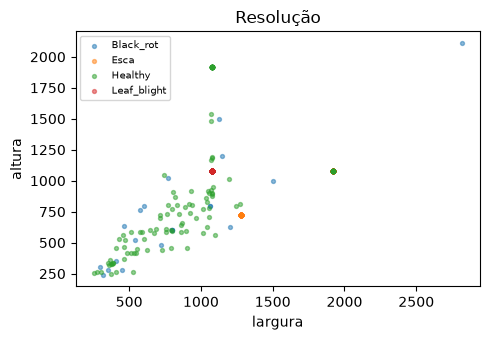

In [4]:
ok = raw[raw.ok].copy()
print(ok.groupby("classe")[["w", "h"]].agg(["min", "median", "max"]))
print("\nModo de cor:\n", pd.crosstab(ok.classe, ok["mode"]))
print("\nFormato real:\n", pd.crosstab(ok.classe, ok.fmt))
print(f"\nLado < {MIN_SIDE}px:", int((ok[["w", "h"]].min(axis=1) < MIN_SIDE).sum()))

fig, ax = plt.subplots(figsize=(5, 3.5))
for c, g in ok.groupby("classe"): ax.scatter(g.w, g.h, s=8, alpha=.5, label=c)
ax.set_xlabel("largura"); ax.set_ylabel("altura"); ax.legend(fontsize=7); ax.set_title("Resolução")
plt.tight_layout(); plt.show()

## 5. Duplicados exatos (MD5)

Distingue **mesma classe** (redundância) de **classes diferentes** (rótulo contraditório — pior).

In [5]:
ex = ok[ok.duplicated("md5", keep=False)]
ncls = ex.groupby("md5").classe.nunique()
print(f"Imagens em duplicados exatos: {len(ex)} ({ex.md5.nunique()} grupos)")
print("  grupos dentro de uma só classe:", int((ncls == 1).sum()))
print("  grupos com classes DIFERENTES :", int((ncls > 1).sum()), "← rótulo contraditório")
if len(ex): display(ex.sort_values(["md5", "path"])[["path", "classe", "md5"]].head(40))

Imagens em duplicados exatos: 0 (0 grupos)
  grupos dentro de uma só classe: 0
  grupos com classes DIFERENTES : 0 ← rótulo contraditório


## 6. Limpeza

Cada imagem removida fica com o **motivo** registado.

| # | Regra | Motivo |
|---|---|---|
| 1 | Ficheiro corrompido / ilegível | `corrompido` |
| 2 | Lado < `MIN_SIDE` | `muito_pequena` |
| 3 | Duplicado exato **entre classes** → removem-se **todas** as cópias | `exato_entre_classes` |
| 4 | Duplicado exato na mesma classe → fica a 1.ª (ordem alfabética) | `exato_mesma_classe` |

In [6]:
drop = {}
def mark(p, why): drop.setdefault(p, why)

for _, r in raw[~raw.ok].iterrows(): mark(r.path, "corrompido")
for _, r in ok[ok[["w", "h"]].min(axis=1) < MIN_SIDE].iterrows(): mark(r.path, "muito_pequena")
for _, gdf in ok[~ok.path.isin(drop)].groupby("md5"):
    if len(gdf) < 2: continue
    if gdf.classe.nunique() > 1:
        for p in gdf.path: mark(p, "exato_entre_classes")
    else:
        for p in sorted(gdf.path)[1:]: mark(p, "exato_mesma_classe")

clean = raw[raw.ok & ~raw.path.isin(drop)].sort_values("path").reset_index(drop=True)
clean[["path", "classe", "md5", "w", "h", "bytes"]].to_csv(REPO_DIR / "data" / "manifest_clean.csv", index=False)

rem = pd.DataFrame([dict(path=p, motivo=m) for p, m in drop.items()], columns=["path", "motivo"])
rem = rem.merge(raw[["path", "classe", "md5"]], on="path", how="left")
rem.to_csv(OUT_DIR / "removidas.csv", index=False)

print(f"Antes: {len(raw)} | removidas: {len(rem)} | ficam: {len(clean)}")
if len(rem): display(pd.crosstab(rem.classe, rem.motivo, margins=True))
resumo = pd.DataFrame({"antes": raw.groupby("classe").size(), "depois": clean.groupby("classe").size()}).fillna(0).astype(int)
resumo["removidas"] = resumo.antes - resumo.depois
display(resumo)
rare_cls = resumo.depois.idxmin()
print(f"Classe rara: {rare_cls} ({resumo.depois.min()} imagens)")
if resumo.depois.min() < 25: print("⚠️  Classe rara ficou muito pequena — rever e documentar a decisão.")

Antes: 556 | removidas: 0 | ficam: 556


,antes,depois,removidas
classe,,,
Black_rot,39,39,0
Esca,201,201,0
Healthy,158,158,0
Leaf_blight,158,158,0


Classe rara: Black_rot (39 imagens)


## 7. Inspeção visual — 10 imagens por classe (conjunto limpo)

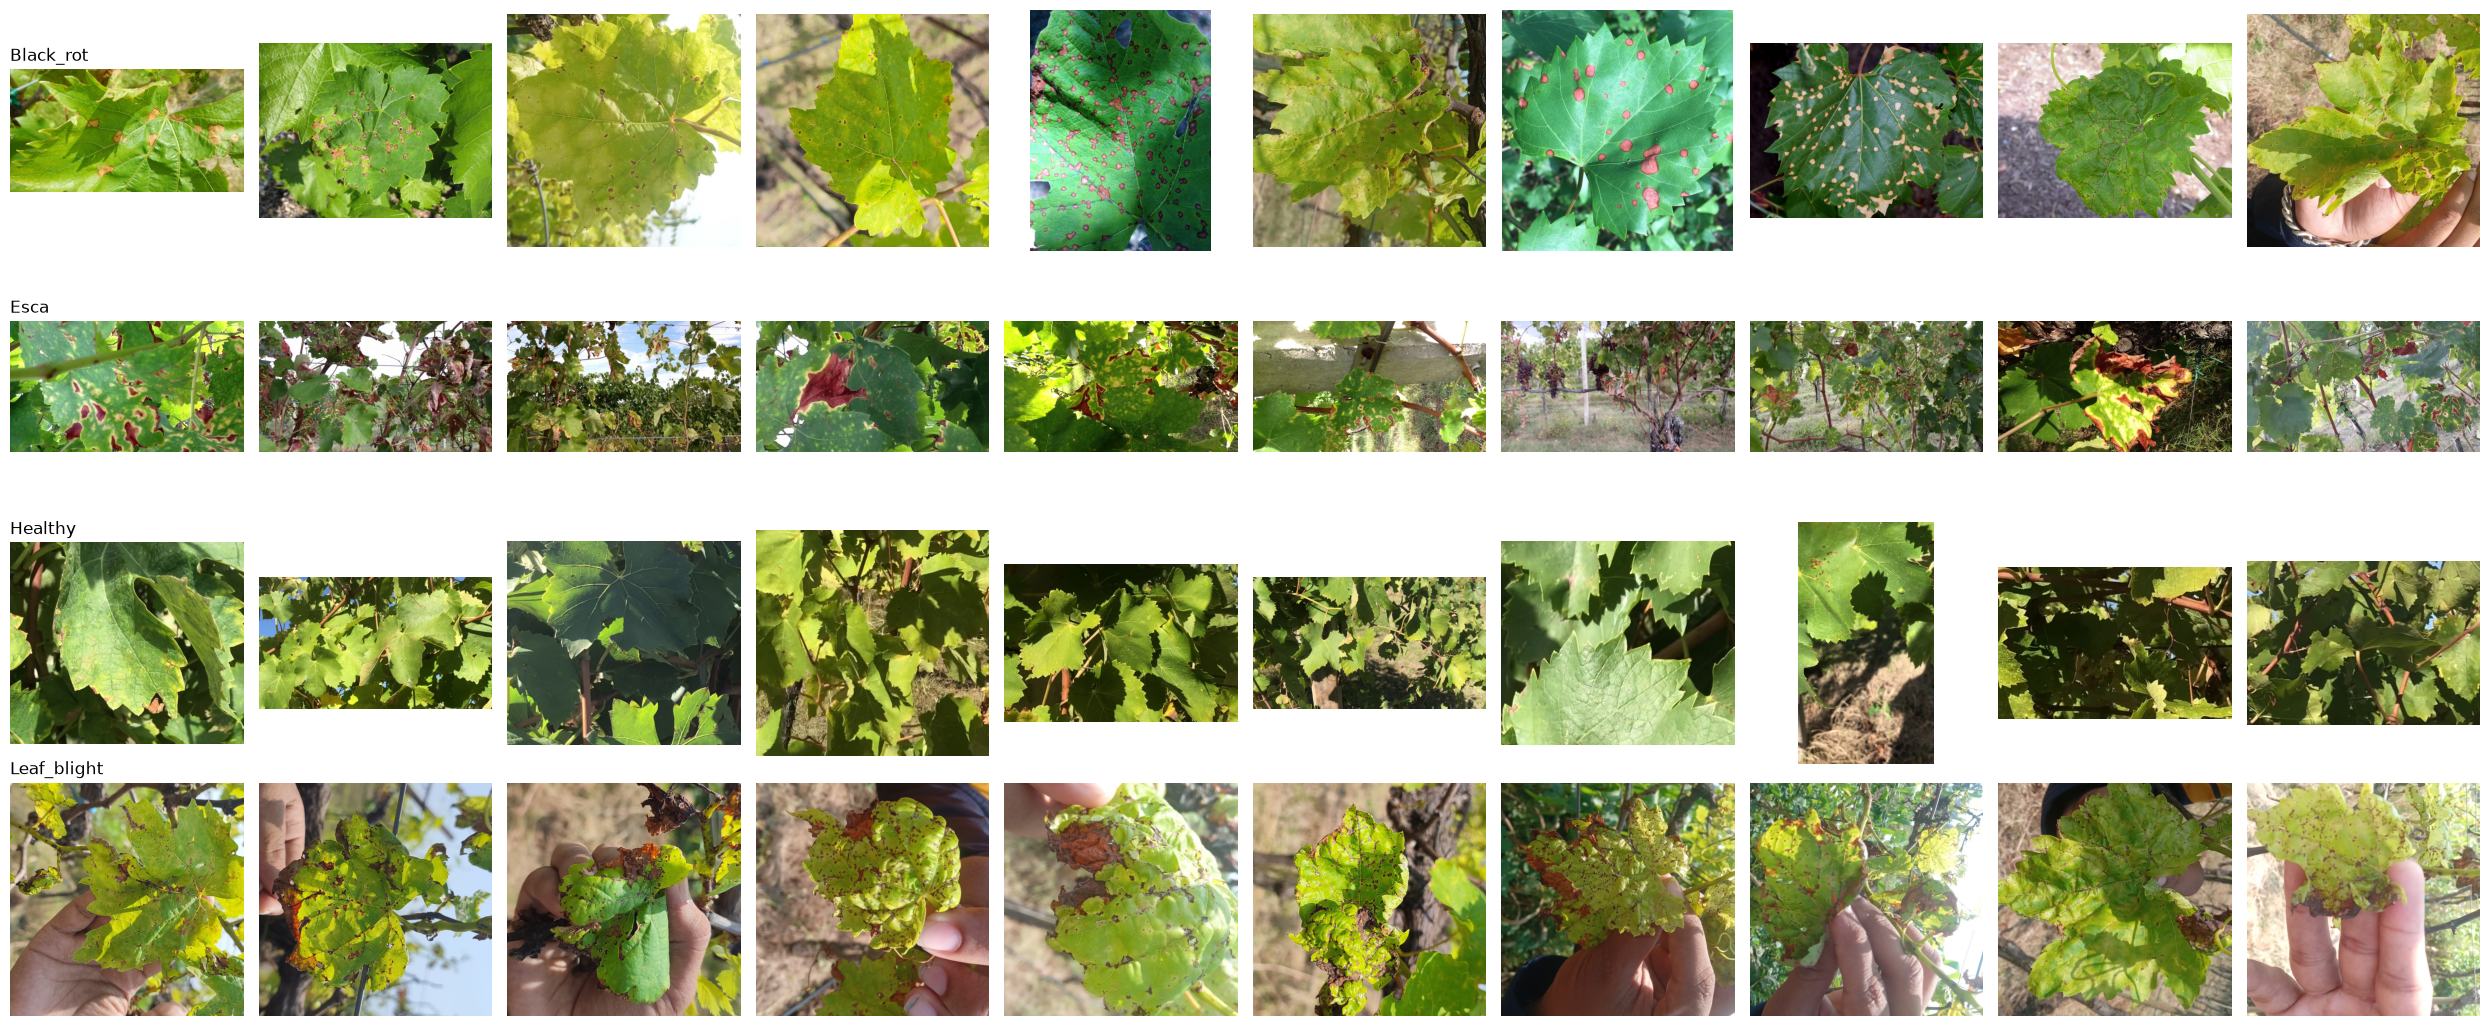

In [7]:
cl = sorted(clean.classe.unique())
fig, axes = plt.subplots(len(cl), 10, figsize=(25, 2.6 * len(cl)))
for i, c in enumerate(cl):
    s = clean[clean.classe == c].sample(10, random_state=0)
    for j, (_, r) in enumerate(s.iterrows()):
        a = axes[i, j]; a.imshow(ImageOps.exif_transpose(Image.open(DATA_DIR / r.path)).convert("RGB")); a.axis("off")
        if j == 0: a.set_title(c, loc="left", fontsize=12)
plt.tight_layout(); plt.show()

## 8. `splits.json` — estratificado, 3 seeds

Por imagem (o dataset não tem identificador de planta — limitação declarada), ~70/15/15 por classe, com ≥ `MIN_TEST_RARE` imagens da classe rara no teste.

In [8]:
def make_split(df, seed):
    rng = np.random.RandomState(seed)
    out = {"train": [], "val": [], "test": []}
    for c, g in df.groupby("classe"):
        ps = list(g.path); rng.shuffle(ps)
        n = len(ps); n_te = int(round(FRAC[2] * n)); n_va = int(round(FRAC[1] * n))
        if c == rare_cls: n_te = max(n_te, MIN_TEST_RARE)
        out["test"] += ps[:n_te]; out["val"] += ps[n_te:n_te + n_va]; out["train"] += ps[n_te + n_va:]
    return {k: sorted(v) for k, v in out.items()}

splits = {"classes": sorted(clean.classe.unique()), "seeds": {str(s): make_split(clean, s) for s in SEEDS}}
splits["sha256"] = hashlib.sha256(json.dumps(splits, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
splits["politica"] = dict(min_side=MIN_SIDE, frac=FRAC, n_imagens=len(clean), data=datetime.date.today().isoformat())
(REPO_DIR / "data" / "splits.json").write_text(json.dumps(splits, indent=1, ensure_ascii=False))
print("sha256:", splits["sha256"])

path2cls = dict(zip(clean.path, clean.classe))
for s in SEEDS:
    sp = splits["seeds"][str(s)]
    print(f"\nSeed {s}:", {k: len(v) for k, v in sp.items()})
    display(pd.DataFrame({k: pd.Series([path2cls[p] for p in v]).value_counts() for k, v in sp.items()}).fillna(0).astype(int)[["train", "val", "test"]])

sha256: d5c573416b133df1effdda10dbfe400e9621d38b54f77c9ae34a3d125fde782c

Seed 0: {'train': 388, 'val': 84, 'test': 84}


,train,val,test
Esca,141,30,30
Healthy,110,24,24
Leaf_blight,110,24,24
Black_rot,27,6,6



Seed 1: {'train': 388, 'val': 84, 'test': 84}


,train,val,test
Esca,141,30,30
Healthy,110,24,24
Leaf_blight,110,24,24
Black_rot,27,6,6



Seed 2: {'train': 388, 'val': 84, 'test': 84}


,train,val,test
Esca,141,30,30
Healthy,110,24,24
Leaf_blight,110,24,24
Black_rot,27,6,6


## 9. Verificação anti-fuga (relê o `splits.json` do disco)

In [9]:
sj = json.loads((REPO_DIR / "data" / "splits.json").read_text())
chk = {k: sj[k] for k in ("classes", "seeds")}
assert hashlib.sha256(json.dumps(chk, sort_keys=True, ensure_ascii=False).encode()).hexdigest() == sj["sha256"], "hash não confere!"

total = set(clean.path); path2md5 = dict(zip(clean.path, clean.md5))
for s in SEEDS:
    sp = sj["seeds"][str(s)]
    tr, va, te = map(set, (sp["train"], sp["val"], sp["test"]))
    assert not (tr & va) and not (tr & te) and not (va & te), f"seed {s}: sobreposição entre splits"
    assert (tr | va | te) == total and sum(len(v) for v in sp.values()) == len(total), f"seed {s}: faltam/sobram imagens"
    md5_split = {}
    for k in sp:
        for p in sp[k]: md5_split.setdefault(path2md5[p], set()).add(k)
    assert all(len(v) == 1 for v in md5_split.values()), f"seed {s}: MD5 em vários splits (FUGA)"
    n_rare_te = sum(path2cls[p] == rare_cls for p in te)
    assert n_rare_te >= MIN_TEST_RARE, f"seed {s}: só {n_rare_te} imagens de {rare_cls} no teste"
    print(f"✅ seed {s}: sem sobreposição, sem MD5 repetido entre splits, {n_rare_te} × {rare_cls} no teste")
assert all((DATA_DIR / p).exists() for p in total), "há caminhos que não existem"

✅ seed 0: sem sobreposição, sem MD5 repetido entre splits, 6 × Black_rot no teste
✅ seed 1: sem sobreposição, sem MD5 repetido entre splits, 6 × Black_rot no teste
✅ seed 2: sem sobreposição, sem MD5 repetido entre splits, 6 × Black_rot no teste


## 10. Resumo para o D1 (tabela 2.1 corrigida + limitações)

In [10]:
print("N.º de imagens:", {c: int(v) for c, v in raw.groupby("classe").size().items()}, "| total", len(raw), "(protocolo: 555)")
print(f"Após limpeza: {len(clean)} →", {c: int(v) for c, v in clean.groupby("classe").size().items()})
print("Removidas:", rem.motivo.value_counts().to_dict() if len(rem) else "nenhuma")
sp0 = splits["seeds"]["0"]
print("Seed 0: treino/val/teste =", len(sp0["train"]), len(sp0["val"]), len(sp0["test"]), "| classe rara no teste:", sum(path2cls[p] == rare_cls for p in sp0["test"]))
print("splits.json sha256:", splits["sha256"])
print("\nTexto-base para limitações: sem identificador de planta/parcela (a unidade é a imagem); datasets de origem mistos;"
      "\nduplicados exatos tratados (ver removidas.csv); quase-duplicados não procurados.")

N.º de imagens: {'Black_rot': 39, 'Esca': 201, 'Healthy': 158, 'Leaf_blight': 158} | total 556 (protocolo: 555)
Após limpeza: 556 → {'Black_rot': 39, 'Esca': 201, 'Healthy': 158, 'Leaf_blight': 158}
Removidas: nenhuma
Seed 0: treino/val/teste = 388 84 84 | classe rara no teste: 6
splits.json sha256: d5c573416b133df1effdda10dbfe400e9621d38b54f77c9ae34a3d125fde782c

Texto-base para limitações: sem identificador de planta/parcela (a unidade é a imagem); datasets de origem mistos;
duplicados exatos tratados (ver removidas.csv); quase-duplicados não procurados.
